In [1]:
import pandas as pd
import numpy as np, os
import matplotlib.pyplot as plt

from pathlib import Path

import vivarium.gbd_mapping as gm
from vivarium.artifact import Artifact

# from db_queries import get_ids, get_outputs, get_population, get_covariate_estimates
# from get_draws.api import get_draws

!date
!whoami
!pwd

Thu Oct 29 13:18:29 PDT 2026
lutzes
/mnt/share/homes/lutzes/vivarium_research_alzheimers/verification_and_validation


# V&V List from Docs

    - Verify that all simulants in the model have AD (i.e., all recorded person-time is in one of the “AD” states, not the “susceptible” state)
    - Verify that there are simulant person-years of BBBM-AD, MCI-AD, and AD-dementia for every year and age group of simulation
    - Verify that there are transitions between AD states are at the expected rates
    - Verify other sim mortality against artifact (ACMR - CSMR)
    - Verify Alzheimer’s EMR against artifact
    - Verify the number of new AD-demential cases per year against the AD population model

### Note: This notebook currently only shows results for the baseline scenario.

# Load Data

Results: 

/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/results/model12.1/model_spec/2026_02_04_10_16_58

Artifact:

/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0

In [2]:
if os.sys.platform == 'darwin':
    # Notebook is running on Nathaniel's MacBook
    project_directory = "/Users/ndbs/project_data/vivarium_csu_alzheimers/"
else:
    # Assume we're running on the cluster
    project_directory = '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/'

In [3]:
%cd $project_directory

/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers


In [4]:
locations = [
            'united_states_of_america',
             'brazil',
             'china',
            #  'germany',
            #  'israel',
            #  'japan',
            #  'spain',
            #  'sweden',
            #  'taiwan_(province_of_china)',
            #  'united_kingdom',
            ]



results_dirs = [
    # 'results/abie_consistent_model_test/china/2026_01_11_13_36_17/results/',
    'results/model12.1/model_spec/2026_02_04_10_16_58/results/',
]

artifact_subdirs = ['artifacts/model10.0/' + x + '.hdf' for x in locations]
# Local paths to artifacts, which may be on laptop or cluster
artifact_dirs = [project_directory + artifact_subdir
                 for artifact_subdir in artifact_subdirs]
# Paths to artifacts on cluster, used for mapping locations in results dataframes
cluster_artifact_dirs = ['/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/' + artifact_subdir
                 for artifact_subdir in artifact_subdirs]
# artifact_dirs = ['/ihme/homes/abie/projects/2025/vivarium_csu_alzheimers/china.hdf']
artifact_dirs

['/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/united_states_of_america.hdf',
 '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/brazil.hdf',
 '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/china.hdf']

In [5]:
apath = artifact_dirs[0]
# apath = project_directory + artifact_subdirs[0]
!ls $apath

/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/united_states_of_america.hdf


In [6]:
# .parquet files are now in subfolders...
[x for x in os.listdir(results_dirs[0]) ]#if 'parquet' in x]

['person_time_ever_eligible_for_bbbm_testing',
 'transition_count_alzheimers_disease_and_other_dementias',
 'counts_bbbm_tests',
 'counts_new_simulants',
 'counts_newly_eligible_for_bbbm_testing',
 'treatment_duration',
 'counts_baseline_tests_among_eligible',
 'person_time_alzheimers_disease_and_other_dementias',
 'ylls',
 'ylds',
 'deaths',
 'transition_count_treatment',
 'person_time_eligible_for_bbbm_testing',
 'person_time_treatment']

In [7]:
art = Artifact(apath)

# age_bins is an empty DataFrame with a MultiIndex storing age group data
age_bins = art.load('population.age_bins')
age_dictionary = (
    age_bins
    .reset_index()
    .assign(age_group=lambda df: df['age_group_name'].str.replace(' ', '_'))
    # Filter to ages that actually appear in our sim
    .query("age_start >= 25")
)
age_dictionary

,age_group_id,age_group_name,age_start,age_end,age_group
4,10,25 to 29,25.0,30.0,25_to_29
5,11,30 to 34,30.0,35.0,30_to_34
6,12,35 to 39,35.0,40.0,35_to_39
7,13,40 to 44,40.0,45.0,40_to_44
8,14,45 to 49,45.0,50.0,45_to_49
9,15,50 to 54,50.0,55.0,50_to_54
10,16,55 to 59,55.0,60.0,55_to_59
11,17,60 to 64,60.0,65.0,60_to_64
12,18,65 to 69,65.0,70.0,65_to_69
13,19,70 to 74,70.0,75.0,70_to_74


## Verify that all simulants in the model have AD 

In [8]:
# filters = [('artifact_path', '==', cluster_artifact_dirs[0])]
filters=None
test = pd.read_parquet(results_dirs[0] + 'deaths', filters=filters)
# test['location'] = locations[0]
print(test.memory_usage(deep=True).sum() / 1e6)
test#.artifact_path.unique()

1717.074503


,measure,entity_type,entity,sub_entity,age_group,event_year,sex,artifact_path,scenario,input_draw,random_seed,value
0,deaths,cause,alzheimers_disease_state,alzheimers_disease_state,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,236,2284,0.0
1,deaths,cause,alzheimers_disease_state,alzheimers_disease_state,25_to_29,2022,Male,/mnt/team/simulation_science/pub/models/vivari...,baseline,236,2284,0.0
2,deaths,cause,alzheimers_disease_state,alzheimers_disease_state,25_to_29,2023,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,236,2284,0.0
3,deaths,cause,alzheimers_disease_state,alzheimers_disease_state,25_to_29,2023,Male,/mnt/team/simulation_science/pub/models/vivari...,baseline,236,2284,0.0
4,deaths,cause,alzheimers_disease_state,alzheimers_disease_state,25_to_29,2024,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,236,2284,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
5332495,deaths,cause,other_causes,other_causes,95_plus,2098,Male,/mnt/team/simulation_science/pub/models/vivari...,baseline,236,2787,32.0
5332496,deaths,cause,other_causes,other_causes,95_plus,2099,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,236,2787,384.0
5332497,deaths,cause,other_causes,other_causes,95_plus,2099,Male,/mnt/team/simulation_science/pub/models/vivari...,baseline,236,2787,26.0
5332498,deaths,cause,other_causes,other_causes,95_plus,2100,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,236,2787,361.0


In [9]:
test.random_seed.nunique()

5

In [10]:
test.input_draw.nunique()

25

In [11]:
test.artifact_path.unique()

array(['/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/united_states_of_america.hdf',
       '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/china.hdf',
       '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/brazil.hdf'],
      dtype=object)

In [12]:
[[('artifact_path', '==', artifact_dir)]
                 for artifact_dir in cluster_artifact_dirs
                 ]

[[('artifact_path',
   '==',
   '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/united_states_of_america.hdf')],
 [('artifact_path',
   '==',
   '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/brazil.hdf')],
 [('artifact_path',
   '==',
   '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model10.0/china.hdf')]]

In [13]:
# # Model 10.0 was run with 100 seeds instead of 5, so let's just filter
# # everything to 5 seeds to make it all run faster
# # seeds = [338, 6520, 3585, 7745, 539]
# seeds = [7179, 2599, 1534, 386, 1935]
# seed_filter = ('random_seed', 'in', seeds)

def print_memory_usage(df, label=''):
    """Print the memory usage of a dataframe in megabytes."""
    print(df.memory_usage(deep=True).sum() / 1e6, 'MB', label)

def convert_to_categorical(
        df,
        include_cols=(),
        exclude_cols=(),
        exclude_dtypes=('float', 'category'),
        inplace=False
    ):
    """Convert all columns except float columns to categorical. This
    saves lots of memory, allowing us to load and manipulate larger
    DataFrames.
    """
    if  len(set(include_cols).intersection(exclude_cols)) != 0:
        raise ValueError("A column can't be both included and excluded!")
    if not inplace:
        df = df.copy()
    for col in df:
        if (
            col in include_cols
            or (col not in exclude_cols 
                and df[col].dtype not in exclude_dtypes)
        ):
            df[col] = df[col].astype('category')
    if not inplace:
        return df
    else:
        return None

def load_df(measure):
    # data = pd.DataFrame()
    dfs_by_location = []
    data_all = pd.read_parquet(
        # NOTE: .parquet files are in subfolders after Vivarium update
        results_dirs[0] + measure, #+ '.parquet',
        # # Filter random seeds
        # filters = [seed_filter],
        # # Combine location filters with OR using disjunctive normal form
        # filters=[[('artifact_path', '==', artifact_dir)]
        #          for artifact_dir in cluster_artifact_dirs
        #          ],
    )
    print_memory_usage(data_all, 'for parquet file loaded into memory')
    convert_to_categorical(data_all, inplace=True)
    print_memory_usage(data_all, 'after converting to categorical')
    # Loop through unique locations (artifact paths), and aggregate
    # random seeds for each one, then concatenate
    for location, artifact in zip(locations, cluster_artifact_dirs):
        temp = data_all[data_all.artifact_path == artifact]

        # aggregate by summing value column over random seeds
        cols = [c for c in temp.columns if c not in ['value', 'random_seed']]
        temp = temp.groupby(cols, observed=True)['value'].sum().reset_index()
        
        temp['location'] = location
        # temp['location'] = locations[results_dirs.index(results_dir)].title()
        temp['event_year'] = temp['event_year'].astype(int)
        # data = pd.concat([data, temp], ignore_index=True)
        dfs_by_location.append(temp)
    data = pd.concat(dfs_by_location, ignore_index=True)
    print_memory_usage(data, 'after aggregating seeds')
    convert_to_categorical(data, exclude_cols=['event_year'], inplace=True)
    print_memory_usage(data, 'after converting aggregated data to categoricals')
    return data

In [14]:
person_time = load_df('person_time_alzheimers_disease_and_other_dementias')
person_time
# person_time.loc[person_time.sub_entity == 'susceptible_to_alzheimers_disease_and_other_dementias'].value.sum()

23180.387336 MB for parquet file loaded into memory
959.862256 MB after converting to categorical
908.663121 MB after aggregating seeds
259.164935 MB after converting aggregated data to categoricals


,measure,entity_type,entity,sub_entity,age_group,event_year,sex,treatment,artifact_path,scenario,input_draw,value,location
0,person_time,cause,alzheimers_disease_and_other_dementias,alzheimers_blood_based_biomarker_state,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,1,0.000000,united_states_of_america
1,person_time,cause,alzheimers_disease_and_other_dementias,alzheimers_blood_based_biomarker_state,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,6,0.000000,united_states_of_america
2,person_time,cause,alzheimers_disease_and_other_dementias,alzheimers_blood_based_biomarker_state,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,7,0.000000,united_states_of_america
3,person_time,cause,alzheimers_disease_and_other_dementias,alzheimers_blood_based_biomarker_state,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,24,0.000000,united_states_of_america
4,person_time,cause,alzheimers_disease_and_other_dementias,alzheimers_blood_based_biomarker_state,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,35,0.000000,united_states_of_america
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9598495,person_time,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state,95_plus,2100,Male,waning_effect,/mnt/team/simulation_science/pub/models/vivari...,bbbm_testing_and_treatment,235,6.477755,china
9598496,person_time,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state,95_plus,2100,Male,waning_effect,/mnt/team/simulation_science/pub/models/vivari...,bbbm_testing_and_treatment,236,2.989733,china
9598497,person_time,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state,95_plus,2100,Male,waning_effect,/mnt/team/simulation_science/pub/models/vivari...,bbbm_testing_and_treatment,245,1.993155,china
9598498,person_time,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state,95_plus,2100,Male,waning_effect,/mnt/team/simulation_science/pub/models/vivari...,bbbm_testing_and_treatment,248,0.996578,china


In [15]:
person_time.treatment.unique()

['no_effect_after_treatment', 'no_effect_never_treated', 'susceptible_to_treatment', 'treatment_effect', 'waiting_for_treatment', 'waning_effect']
Categories (6, object): ['no_effect_after_treatment', 'no_effect_never_treated', 'susceptible_to_treatment', 'treatment_effect', 'waiting_for_treatment', 'waning_effect']

In [16]:
person_time.query("location=='china'").artifact_path.nunique()

1

In [17]:
person_time.location.unique()

['united_states_of_america', 'brazil', 'china']
Categories (3, object): ['brazil', 'china', 'united_states_of_america']

In [18]:
person_time.memory_usage(deep=True)

Index                 132
measure           9598676
entity_type       9598670
entity            9598703
sub_entity        9598883
age_group         9600030
event_year       76788000
sex               9598732
treatment         9599136
artifact_path     9599078
scenario          9598825
input_draw        9599256
value            76788000
location          9598814
dtype: int64

In [19]:
person_time.dtypes

measure          category
entity_type      category
entity           category
sub_entity       category
age_group        category
event_year          int64
sex              category
treatment        category
artifact_path    category
scenario         category
input_draw       category
value             float64
location         category
dtype: object

In [ ]:
print_memory_usage(person_time)

259.164935 MB 


In [21]:
assert person_time.loc[person_time.sub_entity == 'susceptible_to_alzheimers_disease_and_other_dementias'].value.sum() == 0, \
       'should be zero years of person-time susceptible'

# Verify that there *are* simulants in BBBM-AD and MCI-AD for all ages and years

In [22]:
person_time.groupby('sub_entity').value.sum()

/tmp/ipykernel_4162720/1434696413.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  person_time.groupby('sub_entity').value.sum()


sub_entity
alzheimers_blood_based_biomarker_state        2.190834e+09
alzheimers_disease_state                      1.555256e+09
alzheimers_mild_cognitive_impairment_state    9.993180e+08
Name: value, dtype: float64

In [23]:
person_time.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack()

/tmp/ipykernel_4162720/63004212.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  person_time.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack()


sub_entity                                     alzheimers_blood_based_biomarker_state  \
location                 event_year age_group                                           
brazil                   2022       25_to_29                             0.000000e+00   
                                    30_to_34                             0.000000e+00   
                                    35_to_39                             5.979466e+00   
                                    40_to_44                             6.592361e+03   
                                    45_to_49                             4.279354e+04   
...                                                                               ...   
united_states_of_america 2100       75_to_79                             1.441330e+06   
                                    80_to_84                             1.506778e+06   
                                    85_to_89                             1.286868e+06   
                                    90_to_94                             6.660557e+05   
                                    95_plus                              1.996280e+05   

sub_entity                                     alzheimers_disease_state  \
location                 event_year age_group                             
brazil                   2022       25_to_29               0.000000e+00   
                                    30_to_34               0.000000e+00   
                                    35_to_39               0.000000e+00   
                                    40_to_44               5.531006e+01   
                                    45_to_49               8.157487e+03   
...                                                                 ...   
united_states_of_america 2100       75_to_79               8.504963e+05   
                                    80_to_84               1.153566e+06   
                                    85_to_89               1.126710e+06   
                                    90_to_94               7.498953e+05   
                                    95_plus                3.297875e+05   

sub_entity                                     alzheimers_mild_cognitive_impairment_state  
location                 event_year age_group                                              
brazil                   2022       25_to_29                                     0.000000  
                                    30_to_34                                     0.000000  
                                    35_to_39                                     2.989733  
                                    40_to_44                                  1073.314168  
                                    45_to_49                                 12776.624230  
...                                                                                   ...  
united_states_of_america 2100       75_to_79                                629919.813826  
                                    80_to_84                                705642.776181  
                                    85_to_89                                670625.029432  
                                    90_to_94                                403540.216290  
                                    95_plus                                 157529.533196  

[3555 rows x 3 columns]

In [ ]:
#assert np.all(person_time.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack().fillna(0) > 0)

## Verify that there are no transitions out of susceptible state during the simulation 

In [24]:
trans = load_df('transition_count_alzheimers_disease_and_other_dementias')
trans.loc[trans.sub_entity == 'susceptible_to_alzheimers_disease_and_other_dementias_to_alzheimers_disease_and_other_dementias'].value.sum()

15613.569829 MB for parquet file loaded into memory
639.912254 MB after converting to categorical
605.777119 MB after aggregating seeds
172.778433 MB after converting aggregated data to categoricals


0.0

In [25]:
assert trans.loc[trans.sub_entity == 'susceptible_to_alzheimers_disease_and_other_dementias_to_alzheimers_disease_and_other_dementias'].value.sum() == 0, \
       'should be zero transitions from susceptible to with-condition'

# And that there *are* transitions out of other states for all ages

In [26]:
# assert np.all(trans.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack() > 0)

## Next look at the transition rates and approximate durations for BBBM and MCI

In [27]:
out_counts = trans.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack()
out_counts.columns = [c.split('_to_')[0] for c in out_counts.columns]
#out_counts

/tmp/ipykernel_4162720/1392242333.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out_counts = trans.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack()


In [28]:
out_counts

alzheimers_blood_based_biomarker_state  \
location                 event_year age_group                                           
brazil                   2022       25_to_29                                      0.0   
                                    30_to_34                                      0.0   
                                    35_to_39                                      0.0   
                                    40_to_44                                    750.0   
                                    45_to_49                                   6075.0   
...                                                                               ...   
united_states_of_america 2100       75_to_79                                 212236.0   
                                    80_to_84                                 222479.0   
                                    85_to_89                                 192396.0   
                                    90_to_94                                  98853.0   
                                    95_plus                                   29627.0   

                                               alzheimers_mild_cognitive_impairment_state  
location                 event_year age_group                                              
brazil                   2022       25_to_29                                          0.0  
                                    30_to_34                                          0.0  
                                    35_to_39                                          0.0  
                                    40_to_44                                        255.0  
                                    45_to_49                                       3267.0  
...                                                                                   ...  
united_states_of_america 2100       75_to_79                                     161439.0  
                                    80_to_84                                     179386.0  
                                    85_to_89                                     167096.0  
                                    90_to_94                                      95444.0  
                                    95_plus                                       35218.0  

[3555 rows x 2 columns]

In [29]:
out_rates = out_counts / person_time.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack()
#out_rates['alzheimers_blood_based_biomarker_state'].unstack()

/tmp/ipykernel_4162720/3100643703.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out_rates = out_counts / person_time.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack()


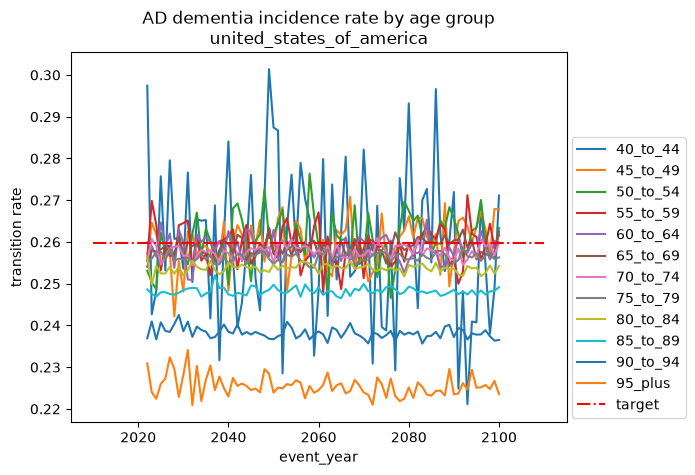

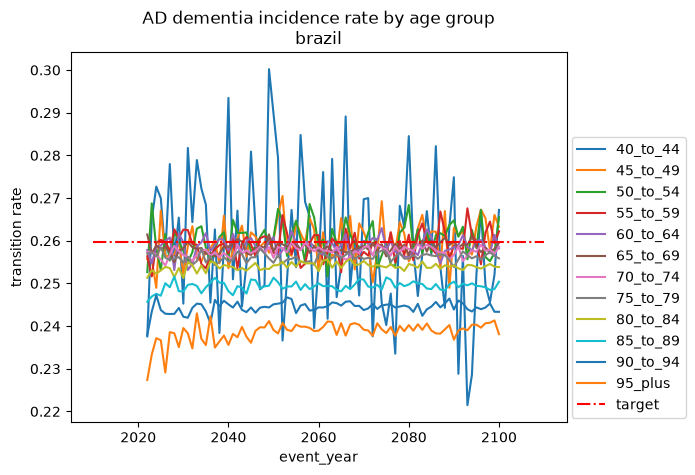

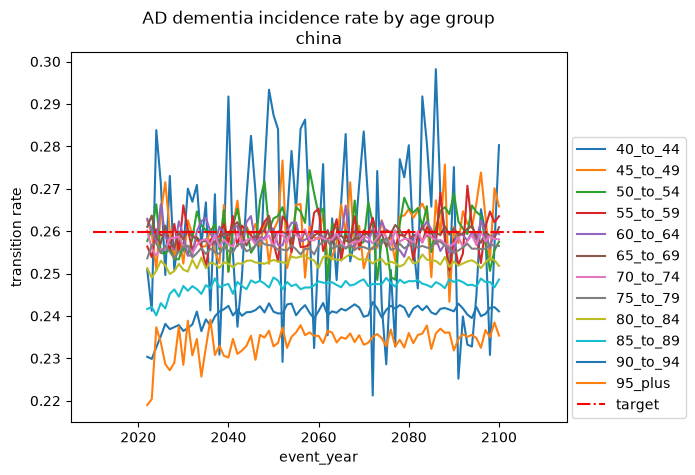

In [30]:
t = out_rates['alzheimers_mild_cognitive_impairment_state'].unstack()
for location in trans.location.unique():
    # .iloc[:,3:] filters out the first 3 age groups, which have 0 or
    # very few people
    t.loc[location].iloc[:,3:].plot(ylabel='transition rate')
    plt.title(f"AD dementia incidence rate by age group\n{location}")
    plt.hlines(1/3.85, 2010, 2110, 'red', ls='-.', label='target')
    plt.legend(loc=(1.01, .01))

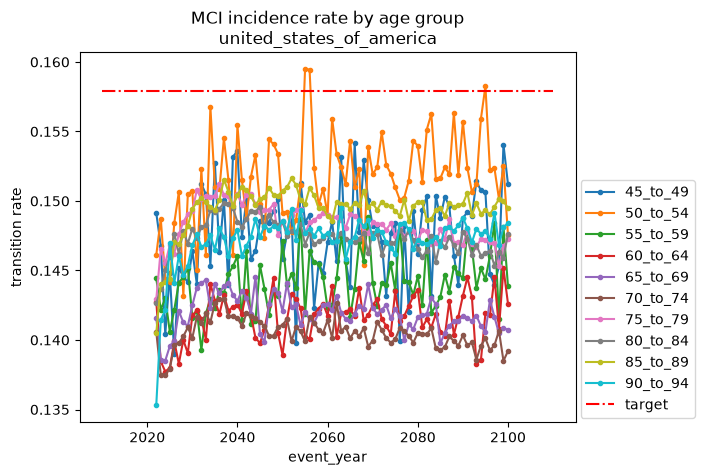

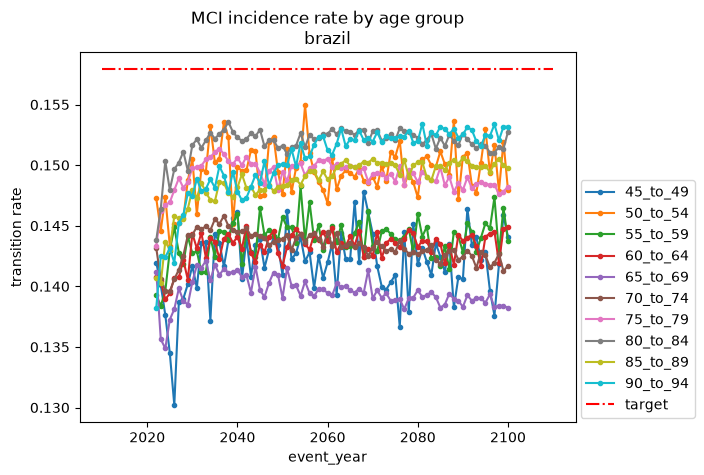

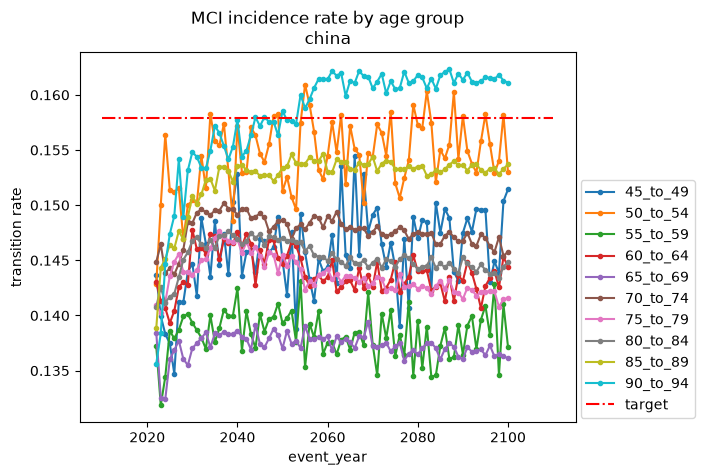

In [31]:
t = out_rates['alzheimers_blood_based_biomarker_state'].unstack()
for location in trans.location.unique():
    t.loc[location].iloc[:,4:14].plot(marker='.', ylabel='transition rate')
    plt.title(location)
    plt.title(f"MCI incidence rate by age group\n{location}")
    # target is 1 / mean of Weibull distribution
    plt.hlines(0.15791673988674756, 2010, 2110, 'red', ls='-.', label='target')
    plt.legend(loc=(1.01, .01))

In [32]:
# prevalence \approx incidence * duration
prevalence_count = person_time.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack()

mci_duration_est = (
    prevalence_count['alzheimers_mild_cognitive_impairment_state']
    / out_counts['alzheimers_blood_based_biomarker_state']
)
#mci_duration_est

/tmp/ipykernel_4162720/1955797147.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  prevalence_count = person_time.groupby(['location', 'event_year', 'age_group', 'sub_entity']).value.sum().unstack()


# Load counts of new simulants

In [33]:
new_sims = load_df('counts_new_simulants')
new_sims.head()

682.568817 MB for parquet file loaded into memory
40.004438 MB after converting to categorical
47.818303 MB after aggregating seeds
11.735367 MB after converting aggregated data to categoricals


,age_group,event_year,sex,artifact_path,scenario,input_draw,value,location
0,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,1,0.0,united_states_of_america
1,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,6,0.0,united_states_of_america
2,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,7,0.0,united_states_of_america
3,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,24,0.0,united_states_of_america
4,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,35,0.0,united_states_of_america


In [34]:
new_sims_by_year_and_age = new_sims.groupby(['location', 'event_year', 'age_group', ]).value.sum()

bbbm_duration_est = (
    prevalence_count['alzheimers_blood_based_biomarker_state']
    / new_sims_by_year_and_age
)
#bbbm_duration_est

/tmp/ipykernel_4162720/2629163193.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  new_sims_by_year_and_age = new_sims.groupby(['location', 'event_year', 'age_group', ]).value.sum()


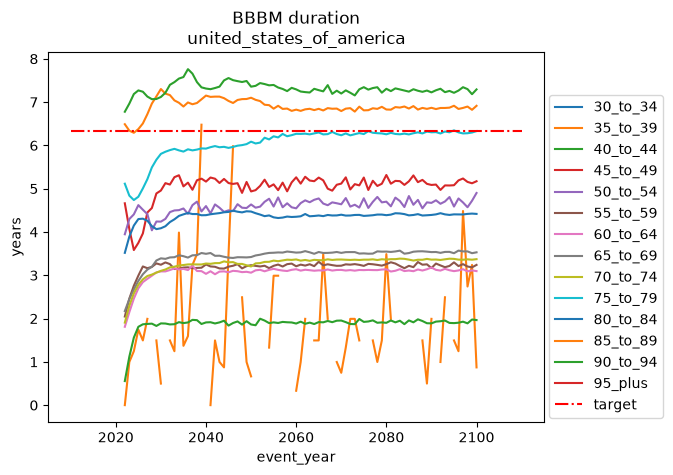

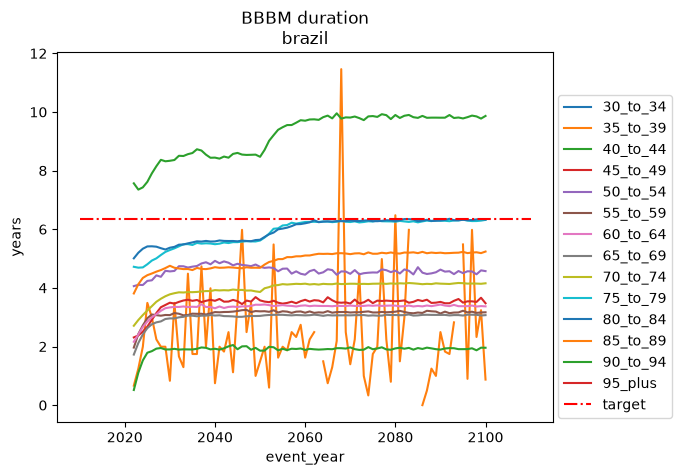

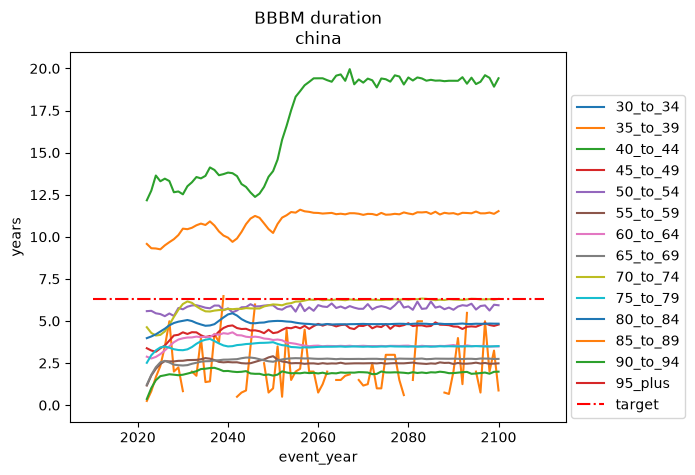

In [35]:
t = bbbm_duration_est.unstack()
for location in trans.location.unique():
    t.loc[location].iloc[:, 1:].plot(ylabel='years')
    # Target is mean of Weibull distribution
    plt.hlines(6.332450889735727, 2010, 2110, 'red', ls='-.', label='target')
    plt.title(f'BBBM duration\n{location}')
    plt.legend(loc=(1.01, .01))

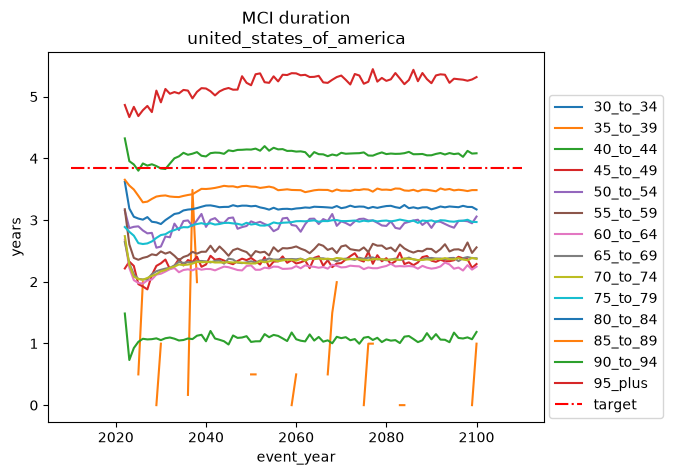

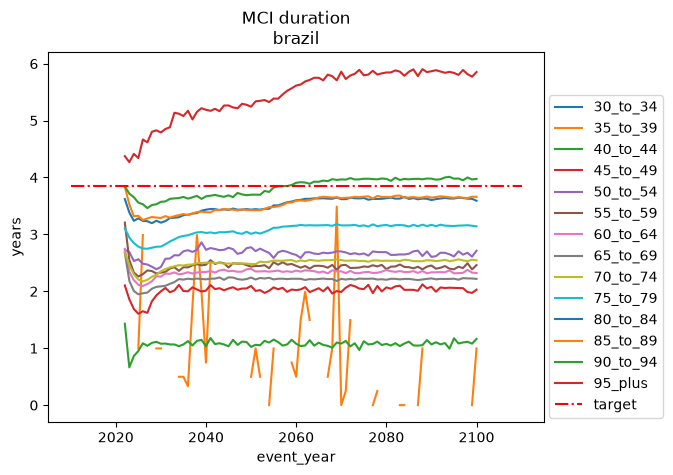

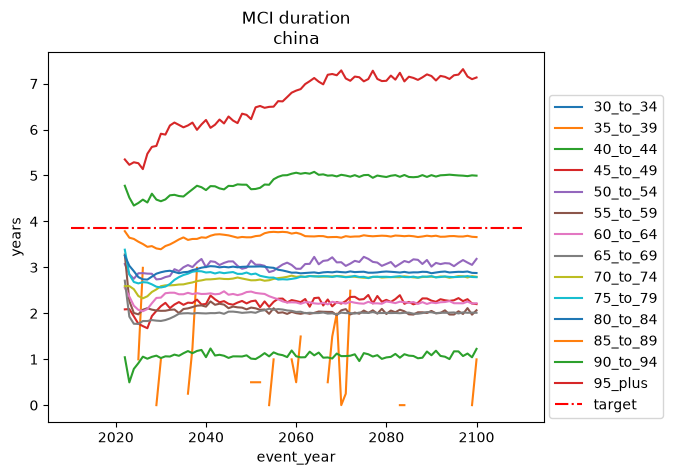

In [36]:
t = mci_duration_est.unstack()
for location in trans.location.unique():
    t.loc[location].iloc[:, 1:].plot(ylabel='years')
    plt.hlines(3.85, 2010, 2110, 'red', ls='-.', label='target')
    plt.title(f'MCI duration\n{location}')
    plt.legend(loc=(1.01, .01))

## Verify Other Cause Mortality in  Sim against artifact (ACMR - CSMR)

In [38]:
%%time

cols = ['input_draw','event_year','location','age_group','sex']

# Load deaths dataframe
deaths = load_df('deaths')

def calculate_ocmr(person_time, deaths):
    # person_time_total = load_df('person_time_alzheimers_disease_and_other_dementias')
    total_pt = person_time.groupby(cols).sum(numeric_only=True)

    # deaths = load_df('deaths')
    other_deaths = deaths[deaths.sub_entity == 'other_causes'].groupby(cols).sum(numeric_only=True)

    ocmr = (other_deaths / total_pt)[['value']].reset_index()

    ocmr2 = ocmr.merge(age_dictionary, on=['age_group'])
    # NOTE: I'm not sure why/whether this .loc was necessary...
    ocmr3 = ocmr2#.loc[ocmr2['age_group_id'].isin(age_group_ids)]
    ocmr4 = ocmr2.groupby([c for c in cols if c != 'input_draw'] + ['age_start']).describe(percentiles=[0.025,0.975])['value'].reset_index()
    return ocmr4

sim_ocmr = calculate_ocmr(person_time, deaths)

1717.074503 MB for parquet file loaded into memory
101.329045 MB after converting to categorical
99.89991 MB after aggregating seeds
27.733724 MB after converting aggregated data to categoricals


<timed exec>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
<timed exec>:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
<timed exec>:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


CPU times: user 28.6 s, sys: 679 ms, total: 29.3 s
Wall time: 27.8 s


In [39]:
art_ocmr = pd.DataFrame()
for artifact_dir in artifact_dirs:
    art = Artifact(artifact_dir)
    
    # TODO: consider better ways to broadcast years from excess mx
    a = art.load(f'cause.all_causes.cause_specific_mortality_rate')
    b = art.load(f'cause.alzheimers_disease_and_other_dementias.cause_specific_mortality_rate')

    data1 = (a - b.droplevel(['year_start', 'year_end'])).dropna()
    data2 = (data1.apply(pd.DataFrame.describe, percentiles=[0.025, 0.975], axis=1)
            .filter(['mean', '2.5%', '97.5%']).reset_index())
    data3 = data2.merge(age_dictionary, on=['age_start','age_end'])
    # NOTE: I'm not sure why/whether this .loc was necessary...
    data4 = data3#.loc[data3['age_group_id'].isin(age_group_ids)]
    data4['measure'] = 'acmr'
    data4['location'] = locations[artifact_dirs.index(artifact_dir)]
    art_ocmr = pd.concat([art_ocmr, data4])
#art_ocmr

In [40]:
art_data = art_ocmr
# location = 'United_States_Of_America'
sex='Female'
year=2030
# art_data.loc[(art_data.location == location) & (art_data.sex == sex) & (art_data.year_start == year)]

In [41]:
def age_group_plot(measure, sim_data, art_data, art_year=None):
    for location in sim_data.location.unique():
        fig, ax = plt.subplots(nrows=3, sharex=True, sharey=True)
        for i, year in enumerate([2030,2040,2050]):
            for j, sex in enumerate(sim_data.sex.unique()):
                color = f'C{j}'
                plot_data = sim_data.loc[(sim_data.location == location) & (sim_data.event_year == year) & (sim_data.sex == sex)]
                if art_year is None:
                    art_plot = art_data.loc[(art_data.location == location) & (art_data.sex == sex) & (art_data.year_start == year)]
                else:
                    art_plot = art_data.loc[(art_data.location == location) & (art_data.sex == sex) & (art_data.year_start == art_year)]

                ax[i].fill_between(plot_data.age_start, plot_data['2.5%'], plot_data['97.5%'], alpha=0.2, color=color)
                ax[i].fill_between(art_plot.age_start, art_plot['2.5%'], art_plot['97.5%'], alpha=0.2, color=color)

                ax[i].plot(art_plot.age_start, art_plot['mean'], linestyle='--', label=f'Artifact {sex}', color=color, linewidth=3)
                ax[i].plot(plot_data.age_start, plot_data['mean'], label=f'Simulation {sex}', color=color)

                if i == 0:
                    ax[i].set_title(f"{measure} in {location}")

                ax[i].text(.5, .95, f"{year}", va='top', ha='center', transform=ax[i].transAxes)
#                 ax[i].tick_params(axis='x', labelrotation=90)
                
                if i == 2:
                    ax[i].set_xlabel("Age Group")
                    
                if i == 1:
                    ax[i].set_ylabel(f"{measure}")
                    ax[i].legend(loc=(1.01, 0))
#                 ax[i].semilogy()
        plt.subplots_adjust(hspace=0)


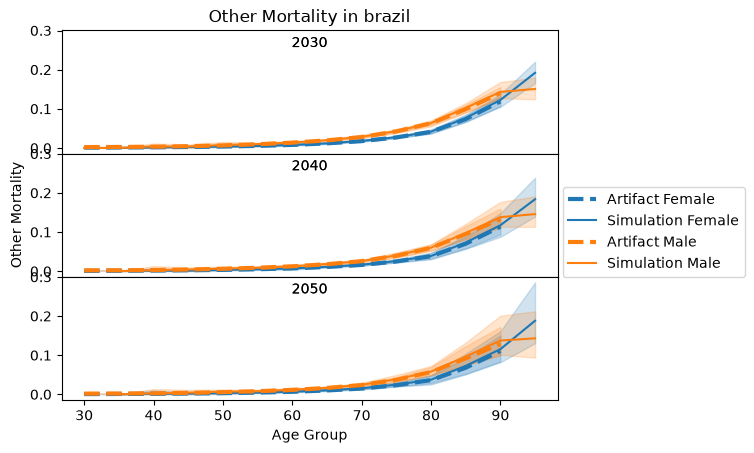

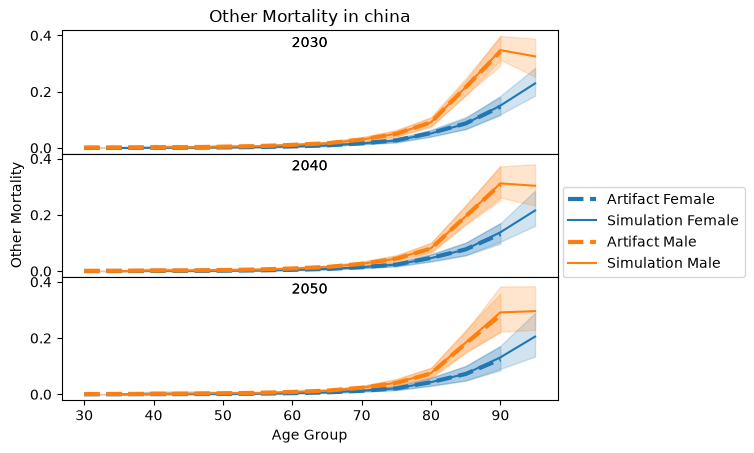

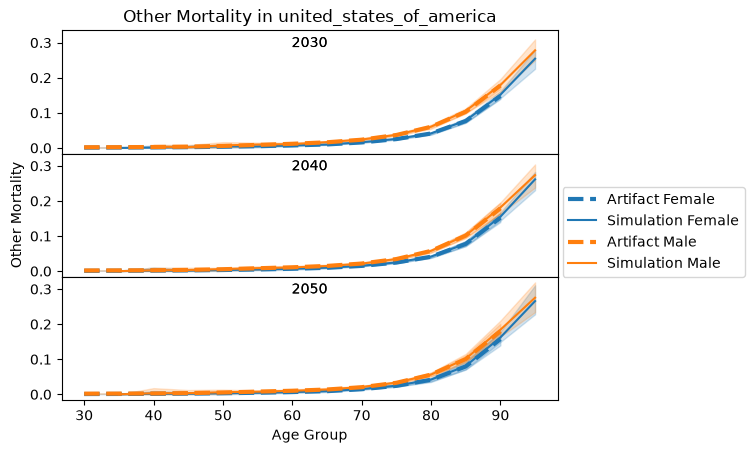

In [42]:
age_group_plot('Other Mortality', sim_ocmr, art_ocmr)

In [43]:
def over_time_plot(measure, sim_data, age_start):
    for location in sim_data.location.unique():
        for sex in sim_data.sex.unique():
            plot_data = sim_data.loc[(sim_data.location == location) & (sim_data.age_start == age_start) & (sim_data.sex == sex)]

            plt.plot(plot_data.event_year, plot_data['mean'], label=f'Simulation {sex}')
            plt.fill_between(plot_data.event_year, plot_data['2.5%'], plot_data['97.5%'], alpha=0.2)

            plt.title(f"{measure} in {location} Over Time Among Age Start Group {age_start}")
            plt.tick_params(axis='x', labelrotation=90)
            plt.xlabel("Year")
            plt.ylabel(f"{measure}")
            plt.legend()
        plt.figure()

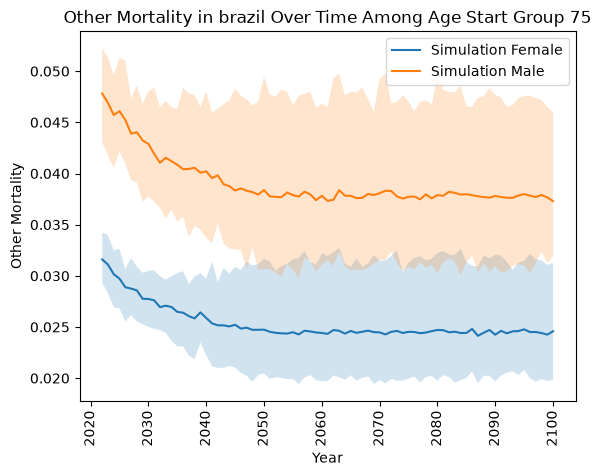

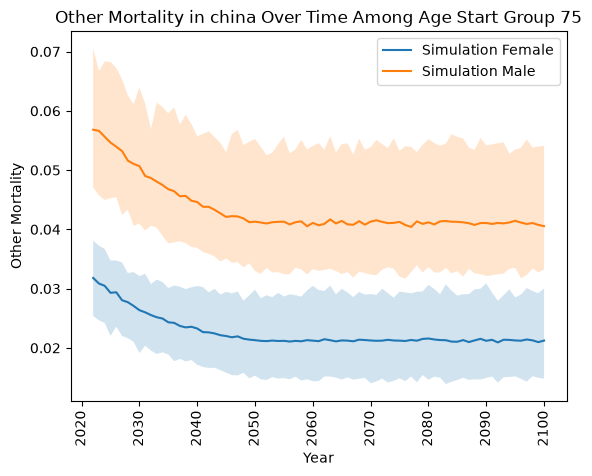

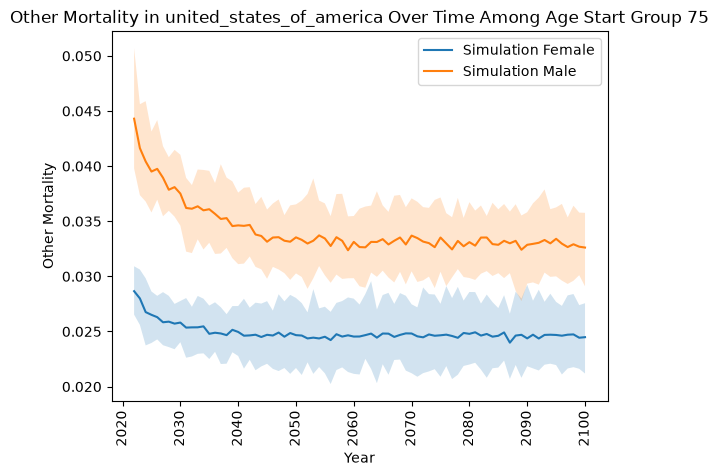

<Figure size 640x480 with 0 Axes>

In [44]:
over_time_plot('Other Mortality', sim_ocmr, 75)

## Validate Alzheimer’s dementia EMR against GBD

In [45]:
cols = ['input_draw','event_year','location','age_group','sex', 'scenario']
scenario = 'baseline'
# severity = 'severe'

def calculate_emr(person_time, deaths):
    # person_time_total = load_df('person_time_alzheimers_disease_and_other_dementias')
    infected = person_time.loc[
        (person_time.sub_entity == f'alzheimers_disease_state')
        & (person_time.scenario == scenario)
    ].groupby(cols, observed=True).sum(numeric_only=True)
    assert len(infected) > 0

    # deaths0 = load_df('deaths')
    deaths = deaths.loc[
        (deaths.sub_entity == f'alzheimers_disease_state')
        & (deaths.scenario == scenario)
    ].groupby(cols, observed=True).sum(numeric_only=True)
    assert len(deaths) > 0
    
    mr = (deaths / infected)[['value']].reset_index()

    mr = mr.merge(age_dictionary, on=['age_group'])
    # mr = mr.loc[mr['age_group_id'].isin(age_group_ids)]
    mr1 = mr.groupby([c for c in cols if c != 'input_draw'] + ['age_start']
                    ).describe(percentiles=[0.025,0.975])['value'].reset_index()
    return mr1

sim_emr = calculate_emr(person_time, deaths)

/tmp/ipykernel_4162720/1372640935.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mr1 = mr.groupby([c for c in cols if c != 'input_draw'] + ['age_start']


In [46]:
sim_emr

,event_year,location,age_group,sex,scenario,age_start,count,mean,std,min,2.5%,50%,97.5%,max
0,2022,brazil,25_to_29,Female,baseline,25.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022,brazil,25_to_29,Male,baseline,25.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022,brazil,30_to_34,Female,baseline,30.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022,brazil,30_to_34,Male,baseline,30.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2022,brazil,35_to_39,Female,baseline,35.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7105,2100,united_states_of_america,85_to_89,Male,baseline,85.0,25.0,0.111690,0.015227,0.086262,0.089739,0.108184,0.138680,0.142276
7106,2100,united_states_of_america,90_to_94,Female,baseline,90.0,25.0,0.077557,0.006227,0.069322,0.069693,0.076454,0.090212,0.092491
7107,2100,united_states_of_america,90_to_94,Male,baseline,90.0,25.0,0.138913,0.018748,0.107328,0.110443,0.136319,0.175688,0.176929
7108,2100,united_states_of_america,95_plus,Female,baseline,95.0,25.0,0.125216,0.023839,0.076493,0.081913,0.128300,0.161385,0.162818


In [47]:
def load_artifact_cause_data(measure, year_start=2025):
    # out = pd.DataFrame()
    artifact_data = []
    for artifact_dir in artifact_dirs:
        art = Artifact(artifact_dir, filter_terms = [f'year_start=={year_start}'])
        data = art.load(f'cause.{measure}')
        data = (data.apply(pd.DataFrame.describe, percentiles=[0.025, 0.975], axis=1)
                .filter(['mean', '2.5%', '97.5%']).reset_index())
        data = data.merge(age_dictionary, on=['age_start','age_end'])
        # data = data.loc[data['age_group_id'].isin(age_group_ids)]
        data['measure'] = measure
        data['location'] = locations[artifact_dirs.index(artifact_dir)]
        # out = pd.concat([out, data])
        artifact_data.append(data)
    out = pd.concat(artifact_data)
    return out

In [49]:
art_emr = load_artifact_cause_data(f'alzheimers_consistent.excess_mortality_rate')
art_emr.head()

,sex,age_start,age_end,year_start,year_end,mean,2.5%,97.5%,age_group_id,age_group_name,age_group,measure,location
0,Male,30,35,2025,2026,8.457607e-09,3.059188e-10,2.361783e-08,11,30 to 34,30_to_34,alzheimers_consistent.excess_mortality_rate,united_states_of_america
1,Male,35,40,2025,2026,7.859428e-09,1.754442e-10,2.269876e-08,12,35 to 39,35_to_39,alzheimers_consistent.excess_mortality_rate,united_states_of_america
2,Male,40,45,2025,2026,4.657251e-03,3.360544e-03,5.947937e-03,13,40 to 44,40_to_44,alzheimers_consistent.excess_mortality_rate,united_states_of_america
3,Male,45,50,2025,2026,1.756943e-02,1.377623e-02,2.114747e-02,14,45 to 49,45_to_49,alzheimers_consistent.excess_mortality_rate,united_states_of_america
4,Male,50,55,2025,2026,2.927732e-02,2.317085e-02,3.497669e-02,15,50 to 54,50_to_54,alzheimers_consistent.excess_mortality_rate,united_states_of_america


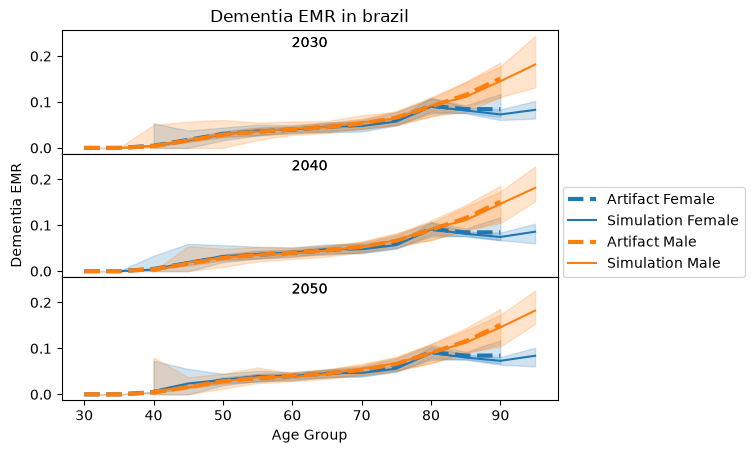

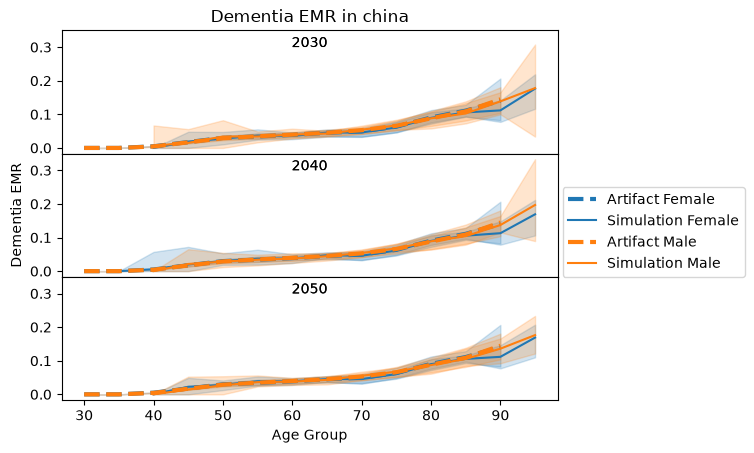

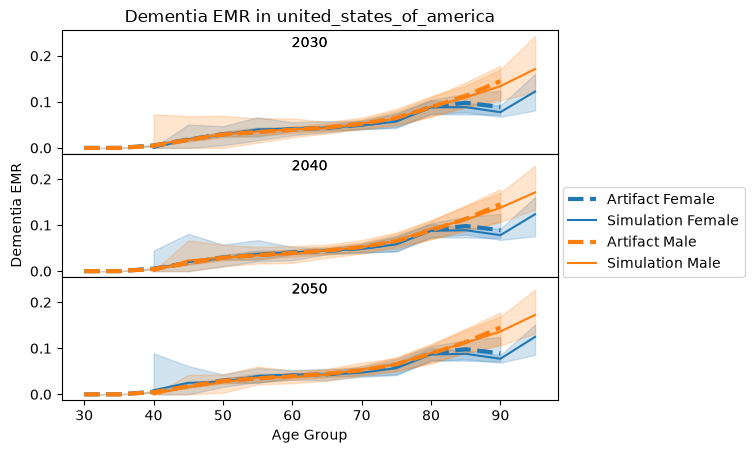

In [50]:
age_group_plot(f'Dementia EMR', sim_emr, art_emr, art_year=2025)

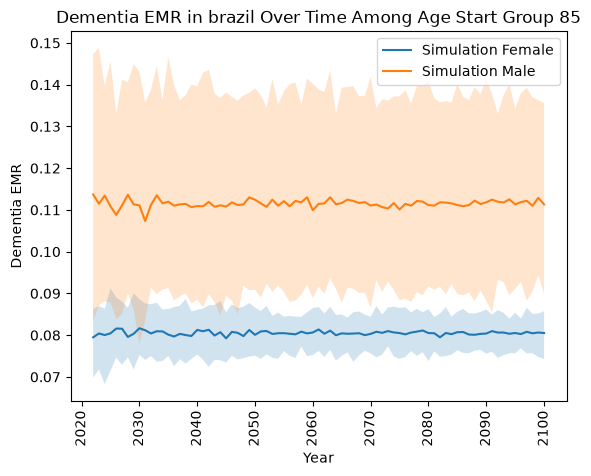

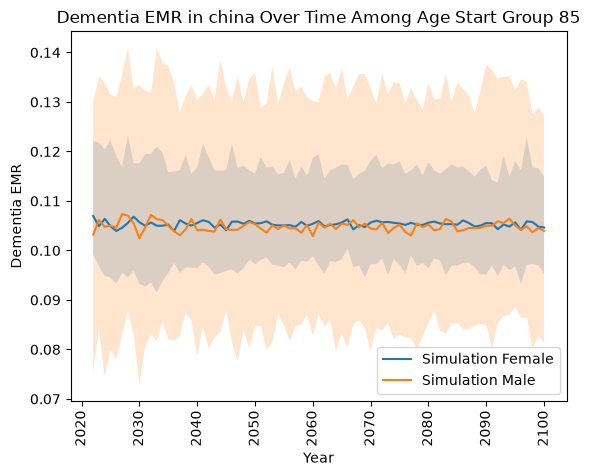

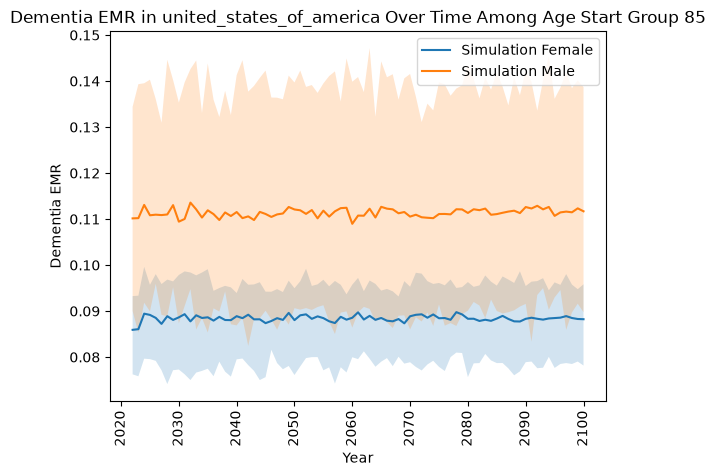

<Figure size 640x480 with 0 Axes>

In [51]:
over_time_plot(f'Dementia EMR', sim_emr, 85)

## Verify the number of new simulants per year against the AD population model

In [52]:
art_incidence_data = []
for artifact_dir in artifact_dirs:
    art = Artifact(artifact_dir)
    df = pd.merge(
        art.load(
            # TODO: Which of these keys should I use?
            # # Output of MCMC, incidence of BBBM used in simulation:
            # 'cause.alzheimers_consistent.population_incidence_dementia'
            # # Used as input (target for calibration):
            'cause.alzheimers.population_incidence_rate'
        ).droplevel(['year_start', 'year_end']),
        art.load('population.structure'),
        left_index=True,
        right_index=True,
        suffixes=['', '_pop']
    )
    # df['location'] = df.location.str.replace(' ', '_').str.lower()
    art_incidence_data.append(df)
    
art_incidence_data = pd.concat(art_incidence_data)
for i in range(500):
    art_incidence_data[f'draw_{i}'] *= art_incidence_data[f'draw_{i}_pop']
    del art_incidence_data[f'draw_{i}_pop']
art_incidence_data.tail()
    

draw_0  \
sex  age_start age_end location year_start year_end                 
Male 95.0      125.0   China    2046       2047      10036.380458   
                                2047       2048      10886.414243   
                                2048       2049      11909.983883   
                                2049       2050      12854.593501   
                                2050       2051      13543.099558   

                                                           draw_1  \
sex  age_start age_end location year_start year_end                 
Male 95.0      125.0   China    2046       2047      10975.540686   
                                2047       2048      11976.340384   
                                2048       2049      13181.044703   
                                2049       2050      14341.664939   
                                2050       2051      15274.164458   

                                                           draw_2  \
sex  age_start age_end location year_start year_end                 
Male 95.0      125.0   China    2046       2047      14639.345612   
                                2047       2048      16105.125421   
                                2048       2049      17886.225848   
                                2049       2050      19614.244921   
                                2050       2051      20998.739880   

                                                           draw_3  \
sex  age_start age_end location year_start year_end                 
Male 95.0      125.0   China    2046       2047      17252.333916   
                                2047       2048      19077.944375   
                                2048       2049      21286.719206   
                                2049       2050      23469.834134   
                                2050       2051      25309.259500   

                                                          draw_4  \
sex  age_start age_end location year_start year_end                
Male 95.0      125.0   China    2046       2047      6571.742477   
                                2047       2048      7008.987709   
                                2048       2049      7534.143545   
                                2049       2050      7999.585874   
                                2050       2051      8307.429211   

                                                           draw_5  \
sex  age_start age_end location year_start year_end                 
Male 95.0      125.0   China    2046       2047      15242.188853   
                                2047       2048      16914.983116   
                                2048       2049      18965.253790   
                                2049       2050      21015.394615   
                                2050       2051      22728.522683   

                                                           draw_6  \
sex  age_start age_end location year_start year_end                 
Male 95.0      125.0   China    2046       2047      11788.453044   
                                2047       2048      12854.725663   
                                2048       2049      14117.323639   
                                2049       2050      15321.262643   
                                2050       2051      16251.736589   

                                                           draw_7  \
sex  age_start age_end location year_start year_end                 
Male 95.0      125.0   China    2046       2047      13249.262998   
                                2047       2048      14798.124330   
                                2048       2049      16678.689818   
                                2049       2050      18582.650203   
                                2050       2051      20241.882373   

                                                           draw_8  \
sex  age_start age_end location year_start year_end                 
Male 95.0      125.0   China    2046       2047      316

In [53]:
scale = pd.DataFrame()
for artifact_dir in artifact_dirs:
    art = Artifact(artifact_dir)
    temp = art.load('population.structure').reset_index() 
    temp['location'] = temp.location.str.replace(' ', '_').str.lower()
    
    df_prev_pop = pd.merge(
        art.load('population.scaling_factor').query("year_start == 2025"),
        art.load('population.structure').query("year_start==2025").droplevel(['year_start', 'year_end']),
        left_index=True,
        right_index=True,
        suffixes=['_prev', '_pop']
    )
    prev = ((df_prev_pop.filter(like='draw_').filter(like='_prev')
            * df_prev_pop.filter(like='draw_').filter(like='_pop').values).mean(axis=1)).sum(axis=0)
    # TODO: use draw-specific scale instead of mean
    
    # NOTE: population 100_000 for V&V (5 seeds), 2_000_000 for final
    # runs (100 seeds)
    # ratio = 2_000_000 / prev
    ratio = 100_000 / prev
    print(ratio)

    temp['ratio'] = ratio

    temp = temp.rename(columns={'year_start': 'event_year'})
    temp = temp.merge(age_dictionary, on=['age_start','age_end'])
    # temp = temp.loc[temp['age_group_id'].isin(age_group_ids)]
    scale = pd.concat([scale, temp], ignore_index=True)
#scale

0.012818306084625083
0.02960834599136685
0.003274362508962734


In [54]:
scale.groupby('location').ratio.describe()/5  # compare to 0.0035494897066482814 in interactive sim for USA

,count,mean,std,min,25%,50%,75%,max
location,,,,,,,,
brazil,180.0,0.005922,6.942752e-19,0.005922,0.005922,0.005922,0.005922,0.005922
china,180.0,0.000655,2.603532e-19,0.000655,0.000655,0.000655,0.000655,0.000655
united_states_of_america,180.0,0.002564,3.471376e-19,0.002564,0.002564,0.002564,0.002564,0.002564


In [55]:
# new_sims = load_df('counts_new_simulants')
new_sims.head()

,age_group,event_year,sex,artifact_path,scenario,input_draw,value,location
0,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,1,0.0,united_states_of_america
1,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,6,0.0,united_states_of_america
2,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,7,0.0,united_states_of_america
3,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,24,0.0,united_states_of_america
4,25_to_29,2022,Female,/mnt/team/simulation_science/pub/models/vivari...,baseline,35,0.0,united_states_of_america


In [56]:
person_time.sub_entity.unique()

['alzheimers_blood_based_biomarker_state', 'alzheimers_disease_state', 'alzheimers_mild_cognitive_impairment_state']
Categories (3, object): ['alzheimers_blood_based_biomarker_state', 'alzheimers_disease_state', 'alzheimers_mild_cognitive_impairment_state']

In [57]:
# trans = load_df('transition_count_alzheimers_disease_and_other_dementias')
new_ad_dementia = trans[trans.sub_entity == 'alzheimers_mild_cognitive_impairment_state_to_alzheimers_disease_state']
new_ad_dementia

,measure,entity_type,entity,sub_entity,age_group,event_year,sex,treatment,artifact_path,scenario,input_draw,value,location
1066500,transition_count,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state_to_...,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,1,0.0,united_states_of_america
1066501,transition_count,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state_to_...,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,6,0.0,united_states_of_america
1066502,transition_count,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state_to_...,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,7,0.0,united_states_of_america
1066503,transition_count,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state_to_...,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,24,0.0,united_states_of_america
1066504,transition_count,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state_to_...,25_to_29,2022,Female,no_effect_after_treatment,/mnt/team/simulation_science/pub/models/vivari...,baseline,35,0.0,united_states_of_america
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6398995,transition_count,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state_to_...,95_plus,2100,Male,waning_effect,/mnt/team/simulation_science/pub/models/vivari...,bbbm_testing_and_treatment,235,0.0,china
6398996,transition_count,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state_to_...,95_plus,2100,Male,waning_effect,/mnt/team/simulation_science/pub/models/vivari...,bbbm_testing_and_treatment,236,2.0,china
6398997,transition_count,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state_to_...,95_plus,2100,Male,waning_effect,/mnt/team/simulation_science/pub/models/vivari...,bbbm_testing_and_treatment,245,0.0,china
6398998,transition_count,cause,alzheimers_disease_and_other_dementias,alzheimers_mild_cognitive_impairment_state_to_...,95_plus,2100,Male,waning_effect,/mnt/team/simulation_science/pub/models/vivari...,bbbm_testing_and_treatment,248,1.0,china


In [58]:
new_sims_with_scale = new_sims.merge(scale[['location','sex','age_group','ratio','event_year']])
new_ad_dementia = new_ad_dementia.merge(scale[['location','sex','age_group','ratio','event_year']])

In [60]:
cols = ['input_draw','event_year','location','age_group','sex', 'scenario']

new_sims_with_scale['total_incidence'] = new_sims_with_scale['value'] / new_sims_with_scale['ratio']
new_ad_dementia['total_incidence'] = new_ad_dementia['value'] / new_ad_dementia['ratio']

def summarize(df):
    df = df.groupby(cols, observed=True).sum(numeric_only=True)
    df = df.groupby([c for c in cols if c != 'input_draw'], observed=True
                    ).describe(percentiles=[0.025,0.975])['total_incidence'].reset_index()

    df = df.merge(age_dictionary, on=['age_group'])
    # df = df.loc[df['age_group_id'].isin(age_group_ids)]

    return df

new_sims_summary = summarize(new_sims_with_scale)

In [61]:
new_ad_dementia_summary = summarize(new_ad_dementia)
new_ad_dementia_summary

,event_year,location,age_group,sex,scenario,count,mean,std,min,2.5%,50%,97.5%,max,age_group_id,age_group_name,age_start,age_end
0,2022,brazil,25_to_29,Female,baseline,25.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10,25 to 29,25.0,30.0
1,2022,brazil,25_to_29,Female,bbbm_testing,25.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10,25 to 29,25.0,30.0
2,2022,brazil,25_to_29,Female,bbbm_testing_and_treatment,25.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10,25 to 29,25.0,30.0
3,2022,brazil,25_to_29,Male,baseline,25.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10,25 to 29,25.0,30.0
4,2022,brazil,25_to_29,Male,bbbm_testing,25.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10,25 to 29,25.0,30.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7825,2050,united_states_of_america,95_plus,Female,bbbm_testing,25.0,24636.640592,3565.862294,18879.249598,19581.370451,24496.216421,31657.849120,32921.666655,235,95 plus,95.0,125.0
7826,2050,united_states_of_america,95_plus,Female,bbbm_testing_and_treatment,25.0,24652.243277,3571.191957,18879.249598,19581.370451,24574.229849,31657.849120,32921.666655,235,95 plus,95.0,125.0
7827,2050,united_states_of_america,95_plus,Male,baseline,25.0,9895.223219,1956.136476,6553.127960,6974.400471,9907.705368,13714.760659,14744.537909,235,95 plus,95.0,125.0
7828,2050,united_states_of_america,95_plus,Male,bbbm_testing,25.0,9895.223219,1956.136476,6553.127960,6974.400471,9907.705368,13714.760659,14744.537909,235,95 plus,95.0,125.0


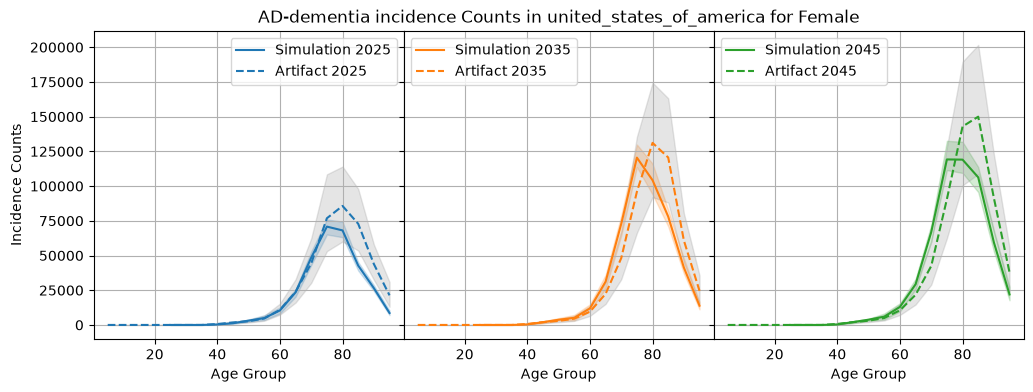

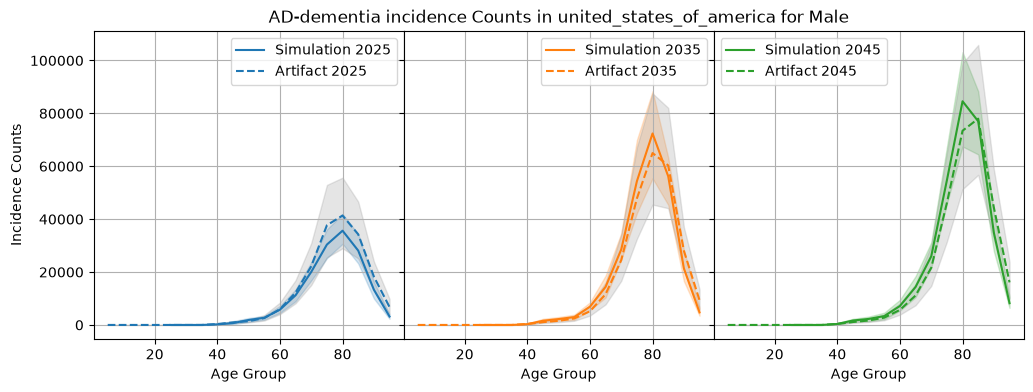

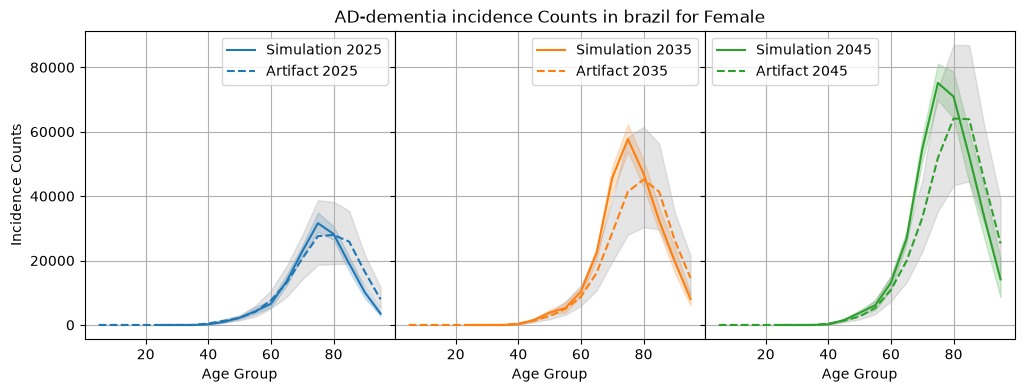

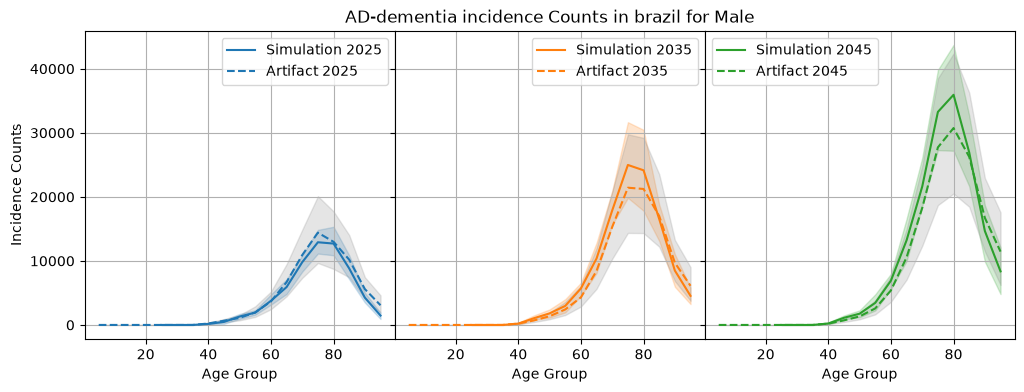

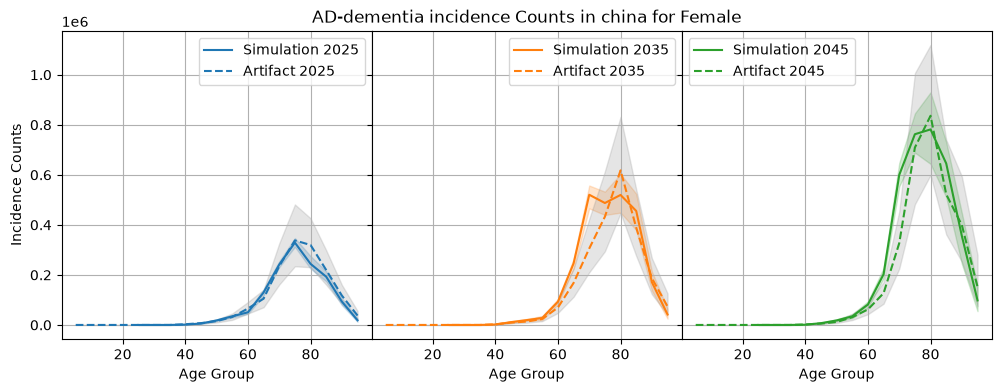

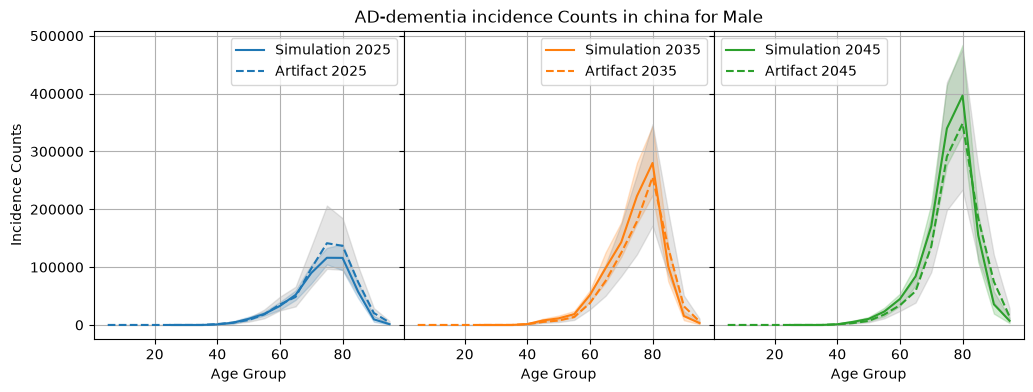

In [62]:
scenario = 'baseline'
for location in new_sims_with_scale.location.unique():
    for sex in new_sims_with_scale.sex.unique():
        fig, ax = plt.subplots(ncols=3, sharex=True, sharey=True, figsize=(12,4))
        plt.subplots_adjust(wspace=0)
        for i, year in enumerate([2025, 2035, 2045]):
            color = f'C{i}'
            plot_data = new_ad_dementia_summary.query(
                'location == @location and event_year == @year and sex == @sex'
                ' and scenario == @scenario'
                )

            location_w_spaces = location.replace('_', ' ').title().replace('Of', 'of')
            art_plot = art_incidence_data.query(
                f'location == "{location_w_spaces}" and year_start == {year} and sex == "{sex}"'
            ).reset_index()

            art_plot['mean'] = art_plot.filter(like='draw_').mean(axis=1)
            art_plot['upper'] = np.percentile(art_plot.filter(like='draw_'), 97.5, axis=1)
            art_plot['lower'] = np.percentile(art_plot.filter(like='draw_'), 2.5, axis=1)

            ax[i].fill_between(plot_data.age_start, plot_data['2.5%'], plot_data['97.5%'], alpha=0.2, color=color)
            ax[i].fill_between(art_plot.age_start, art_plot['upper'], art_plot['lower'], alpha=0.2, color='grey')
            ax[i].plot(plot_data.age_start, plot_data['mean'], label=f'Simulation {year}', color=color)
            ax[i].plot(art_plot.age_start, art_plot['mean'], label=f'Artifact {year}', color=color, linestyle='--')
            ax[i].grid(True)
            if i == 1:
                ax[i].set_title(f"AD-dementia incidence Counts in {location} for {sex}")
#             plt.tick_params(axis='x', labelrotation=90)
            ax[i].set_xlabel("Age Group")
            if i == 0:
                ax[i].set_ylabel(f"Incidence Counts")
            ax[i].legend()#(loc=(1.01, 0))


I did some manual checks against GBD compare to make sure these were less than those, with the expectation they are about half. 

## Verifying Prevalence of AD Dementia

In [64]:
art_prev_data = []
for artifact_dir in artifact_dirs:
    art = Artifact(artifact_dir)
    df = pd.merge(
        art.load(
            # This key is the prevalence of all 5 states:
            # 'cause.alzheimers_consistent.alzheimers_prevalence'
            # This key is the prevalence of the 3 dementia states:
            'cause.alzheimers.prevalence'
                ).droplevel(['year_start', 'year_end']),
        art.load('population.structure'),
        left_index=True,
        right_index=True,
        suffixes=['', '_pop']
    )
    art_prev_data.append(df)
    
art_prev_data = pd.concat(art_prev_data)
for i in range(500):
    art_prev_data[f'draw_{i}'] *= art_prev_data[f'draw_{i}_pop']
    del art_prev_data[f'draw_{i}_pop']
art_prev_data.head()

draw_0  \
sex    age_start age_end location                 year_start year_end           
Female 5.0       10.0    United States of America 2021       2022         0.0   
                                                  2022       2023         0.0   
                                                  2023       2024         0.0   
                                                  2024       2025         0.0   
                                                  2025       2026         0.0   

                                                                       draw_1  \
sex    age_start age_end location                 year_start year_end           
Female 5.0       10.0    United States of America 2021       2022         0.0   
                                                  2022       2023         0.0   
                                                  2023       2024         0.0   
                                                  2024       2025         0.0   
                                                  2025       2026         0.0   

                                                                       draw_2  \
sex    age_start age_end location                 year_start year_end           
Female 5.0       10.0    United States of America 2021       2022         0.0   
                                                  2022       2023         0.0   
                                                  2023       2024         0.0   
                                                  2024       2025         0.0   
                                                  2025       2026         0.0   

                                                                       draw_3  \
sex    age_start age_end location                 year_start year_end           
Female 5.0       10.0    United States of America 2021       2022         0.0   
                                                  2022       2023         0.0   
                                                  2023       2024         0.0   
                                                  2024       2025         0.0   
                                                  2025       2026         0.0   

                                                                       draw_4  \
sex    age_start age_end location                 year_start year_end           
Female 5.0       10.0    United States of America 2021       2022         0.0   
                                                  2022       2023         0.0   
                                                  2023       2024         0.0   
                                                  2024       2025         0.0   
                                                  2025       2026         0.0   

                                                                       draw_5  \
sex    age_start age_end location                 year_start year_end           
Female 5.0       10.0    United States of America 2021       2022         0.0   
                                                  2022       2023         0.0   
                                                  2023       2024         0.0   
                                                  2024       2025         0.0   
                                                  2025       2026         0.0   

                                                                       draw_6  \
sex    age_start age_end location                 year_start year_end           
Female 5.0       10.0    United States of America 2021       2022         0.0   
                                                  2022       2023         0.0   
                                                  2023       2024         0.0   
                                                  2024       2025         0.0   
                                                  2025       2026         0.0   

                                                                       draw_7  \
sex    age_sta

In [66]:
cols = ['input_draw','event_year','location','age_group','sex', 'scenario']
# dementia_states = ['alzheimers_mild_dementia_state', 'alzheimers_moderate_dementia_state', 'alzheimers_severe_dementia_state']
dementia_states = ['alzheimers_disease_state']
scenario = 'baseline'

# # FIXME: Wrong name, and don't reload
# new_sims = load_df('person_time_alzheimers_disease_and_other_dementias')
person_time_dementia = person_time.query("sub_entity in @dementia_states and scenario == @scenario")
person_time_dementia = person_time_dementia.merge(scale[['location','sex','age_group','ratio','event_year']])
person_time_dementia['total_prev'] = person_time_dementia['value'] / person_time_dementia['ratio']
person_time_dementia = person_time_dementia.groupby(cols, observed=True).sum(numeric_only=True)
person_time_dementia = person_time_dementia.groupby(
    [c for c in cols if c != 'input_draw'], observed=True).describe(percentiles=[0.025,0.975])['total_prev'].reset_index()

person_time_dementia = person_time_dementia.merge(age_dictionary, on=['age_group'])
# person_time_dementia = person_time_dementia.loc[person_time_dementia['age_group_id'].isin(age_group_ids)]
person_time_dementia.tail()

,event_year,location,age_group,sex,scenario,count,mean,std,min,2.5%,50%,97.5%,max,age_group_id,age_group_name,age_start,age_end
2605,2050,united_states_of_america,85_to_89,Male,baseline,25.0,445053.285714,34976.615970,372133.343128,375515.313341,438023.452456,501036.943443,515031.302946,31,85 to 89,85.0,90.0
2606,2050,united_states_of_america,90_to_94,Female,baseline,25.0,548084.425164,35980.595082,488714.132435,495454.748930,549861.708821,610744.947305,628774.347132,32,90 to 94,90.0,95.0
2607,2050,united_states_of_america,90_to_94,Male,baseline,25.0,265553.856079,24169.507823,231062.424690,232228.621315,259245.509801,313139.343177,313979.004747,32,90 to 94,90.0,95.0
2608,2050,united_states_of_america,95_plus,Female,baseline,25.0,237335.007605,28847.928413,178078.224681,188597.318241,242724.390942,291712.423848,297963.237760,235,95 plus,95.0,125.0
2609,2050,united_states_of_america,95_plus,Male,baseline,25.0,81896.546743,10694.924782,62741.378440,64304.081918,82916.580058,101124.796700,105346.428484,235,95 plus,95.0,125.0


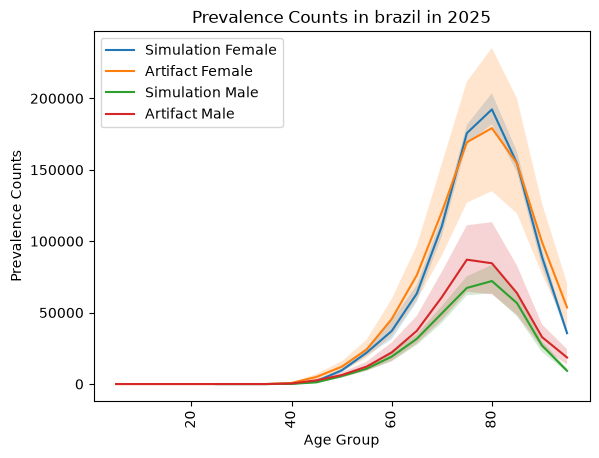

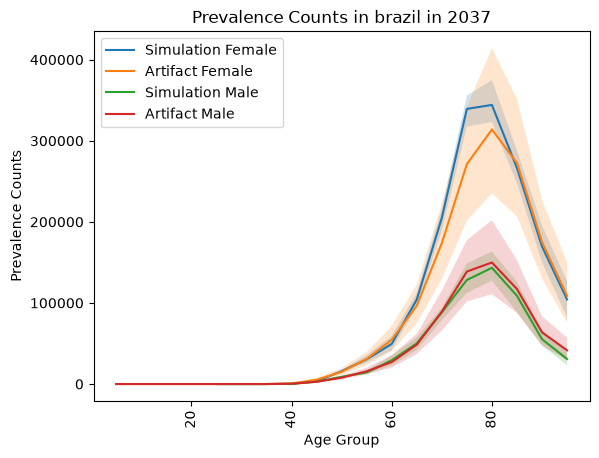

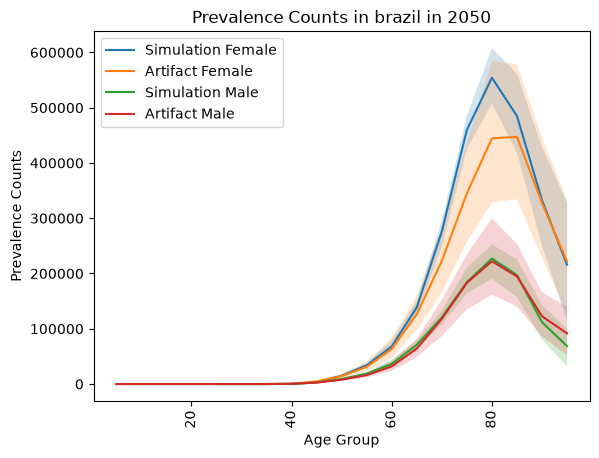

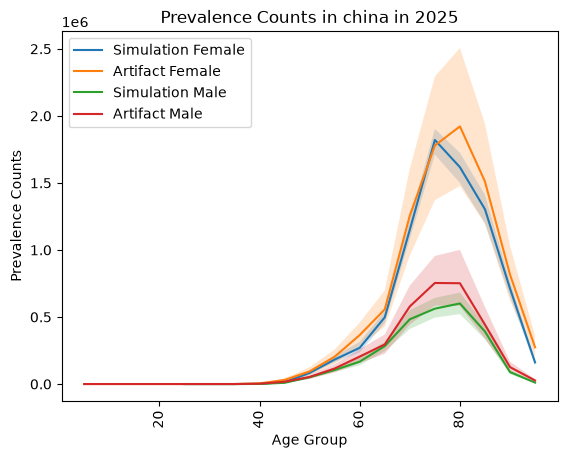

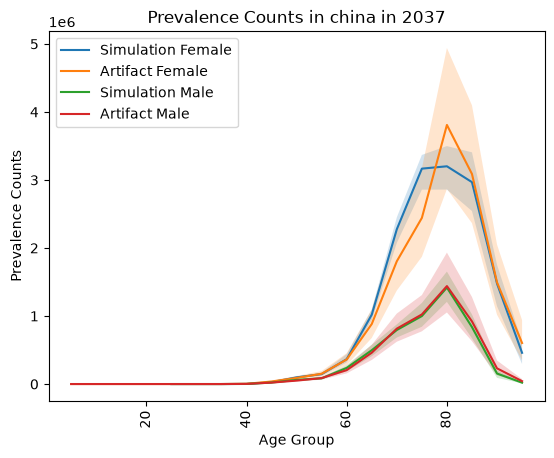

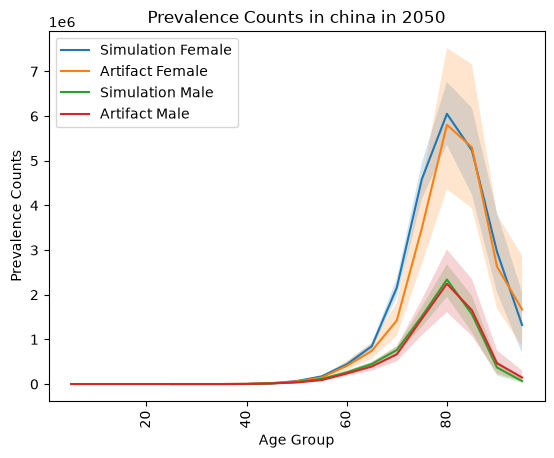

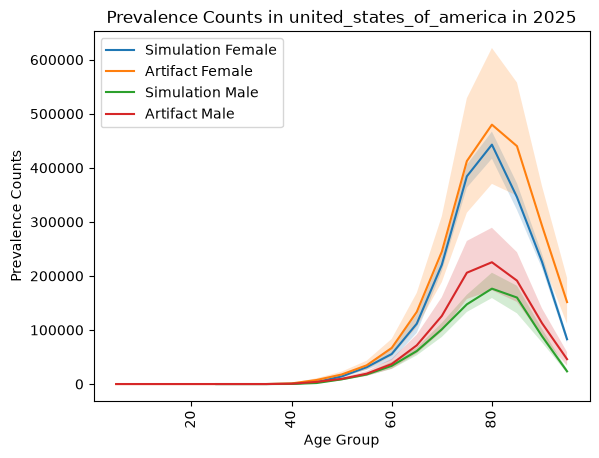

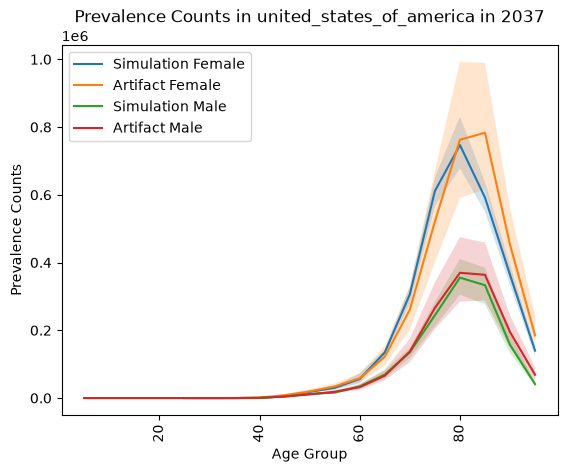

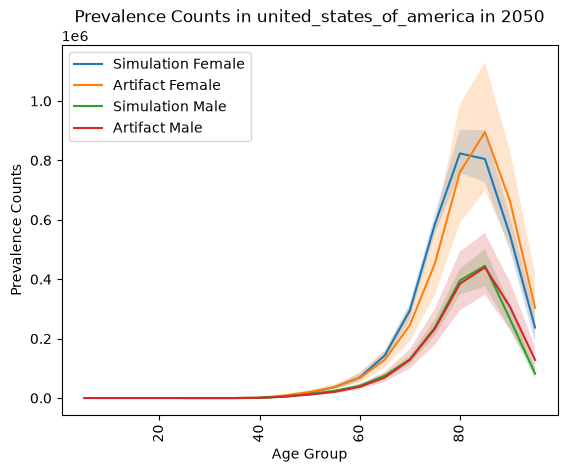

<Figure size 640x480 with 0 Axes>

In [67]:
for location in person_time_dementia.location.unique():
    for year in [2025,2037,2050]:
        for sex in person_time_dementia.sex.unique(): # [:1]:
            plot_data = person_time_dementia.loc[(person_time_dementia.location == location) & (person_time_dementia.event_year == year) & (person_time_dementia.sex == sex) ]
#             gbd_plot = gbd_data.loc[(gbd_data.location_name == location) & (gbd_data.sex == sex) & (gbd_data.measure == 'prevalence')]

            location_w_spaces = location.replace('_', ' ').title().replace('Of', 'of')
            art_plot = art_prev_data.query(
                f'location == "{location_w_spaces}" and year_start == {year} and sex == "{sex}"'
            ).reset_index()
            art_plot['mean'] = art_plot.filter(like='draw_').mean(axis=1)
            art_plot['upper'] = np.percentile(art_plot.filter(like='draw_'), 97.5, axis=1)
            art_plot['lower'] = np.percentile(art_plot.filter(like='draw_'), 2.5, axis=1)

            plt.plot(plot_data.age_start, plot_data['mean'], label=f'Simulation {sex}')
            plt.fill_between(plot_data.age_start, plot_data['2.5%'], plot_data['97.5%'], alpha=0.2)

            plt.plot(art_plot.age_start, art_plot['mean'], label=f'Artifact {sex}')
            plt.fill_between(art_plot.age_start, art_plot['upper'], art_plot['lower'], alpha=0.2)

            plt.title(f"Prevalence Counts in {location} in {year}")
            plt.tick_params(axis='x', labelrotation=90)
            plt.xlabel("Age Group")
            plt.ylabel(f"Prevalence Counts")
            plt.legend()
        plt.figure()

## Total Sim Population Over Time

In [68]:
cols = ['input_draw','event_year','location', 'scenario'] #, 'age_group']

# # FIXME: Don't reload person-time
# person_time_total = load_df('person_time_alzheimers_disease_and_other_dementias')
person_time_total = person_time.groupby(cols)['value'].sum().reset_index()
person_time_total = person_time_total.groupby([c for c in cols if c != 'input_draw'])['value'].describe(percentiles=[0.025,0.975]).reset_index()
person_time_total.head()

/tmp/ipykernel_4162720/1365133097.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  person_time_total = person_time.groupby(cols)['value'].sum().reset_index()
/tmp/ipykernel_4162720/1365133097.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  person_time_total = person_time_total.groupby([c for c in cols if c != 'input_draw'])['value'].describe(percentiles=[0.025,0.975]).reset_index()


,event_year,location,scenario,count,mean,std,min,2.5%,50%,97.5%,max
0,2022,brazil,baseline,25.0,101484.655003,69.772853,101352.449008,101376.665845,101482.502396,101625.710609,101649.927447
1,2022,brazil,bbbm_testing,25.0,101484.655003,69.772853,101352.449008,101376.665845,101482.502396,101625.710609,101649.927447
2,2022,brazil,bbbm_testing_and_treatment,25.0,101484.655003,69.772853,101352.449008,101376.665845,101482.502396,101625.710609,101649.927447
3,2022,china,baseline,25.0,101546.123915,142.392138,101238.340862,101277.805339,101574.187543,101816.256263,101857.215606
4,2022,china,bbbm_testing,25.0,101546.123915,142.392138,101238.340862,101277.805339,101574.187543,101816.256263,101857.215606


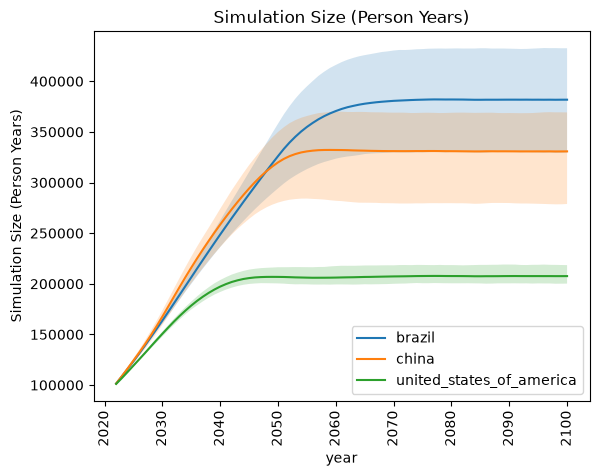

In [69]:
scenario = 'baseline'
for location in person_time_total.location.unique():
    plot_data = person_time_total.loc[
        (person_time_total.location == location) & (person_time_total.scenario == scenario)]
    plt.plot(plot_data.event_year, plot_data['mean'], label=location)
    plt.fill_between(plot_data.event_year, plot_data['2.5%'], plot_data['97.5%'], alpha=0.2)
    plt.title(f"Simulation Size (Person Years)")
    plt.tick_params(axis='x', labelrotation=90)
    plt.xlabel("year")
    plt.ylabel("Simulation Size (Person Years)")
    plt.legend()

# Decompose person-time by state

In [70]:
cols = ["input_draw", "event_year", "sub_entity", "location", "scenario"]  # , 'age_group']

person_time_total = person_time.groupby(cols, observed=True)["value"].sum().reset_index()
person_time_total = (
    person_time_total.groupby([c for c in cols if c != "input_draw"])["value"]
    .describe(percentiles=[0.025, 0.975])
    .reset_index()
)
person_time_total  # .head()

/tmp/ipykernel_4162720/2789164734.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  person_time_total.groupby([c for c in cols if c != "input_draw"])["value"]


,event_year,sub_entity,location,scenario,count,mean,std,min,2.5%,50%,97.5%,max
0,2022,alzheimers_blood_based_biomarker_state,brazil,baseline,25.0,47154.289062,259.430258,46529.713895,46649.303217,47212.867899,47453.740726,47474.967830
1,2022,alzheimers_blood_based_biomarker_state,brazil,bbbm_testing,25.0,47154.289062,259.430258,46529.713895,46649.303217,47212.867899,47453.740726,47474.967830
2,2022,alzheimers_blood_based_biomarker_state,brazil,bbbm_testing_and_treatment,25.0,47154.289062,259.430258,46529.713895,46649.303217,47212.867899,47453.740726,47474.967830
3,2022,alzheimers_blood_based_biomarker_state,china,baseline,25.0,48381.395099,336.539397,47795.865845,47818.288843,48320.563997,48928.875017,48986.277892
4,2022,alzheimers_blood_based_biomarker_state,china,bbbm_testing,25.0,48381.395099,336.539397,47795.865845,47818.288843,48320.563997,48928.875017,48986.277892
...,...,...,...,...,...,...,...,...,...,...,...,...
2128,2100,alzheimers_mild_cognitive_impairment_state,china,bbbm_testing,25.0,71382.009473,6393.284052,57141.273101,59757.887474,72131.794661,80794.346886,81958.548939
2129,2100,alzheimers_mild_cognitive_impairment_state,china,bbbm_testing_and_treatment,25.0,69986.083176,6411.736765,55535.288159,58155.490212,71198.499658,79480.458864,80360.038330
2130,2100,alzheimers_mild_cognitive_impairment_state,united_states_of_america,baseline,25.0,43942.418836,1288.358566,42366.012320,42411.157290,43779.159480,46702.420808,47806.828200
2131,2100,alzheimers_mild_cognitive_impairment_state,united_states_of_america,bbbm_testing,25.0,43942.418836,1288.358566,42366.012320,42411.157290,43779.159480,46702.420808,47806.828200


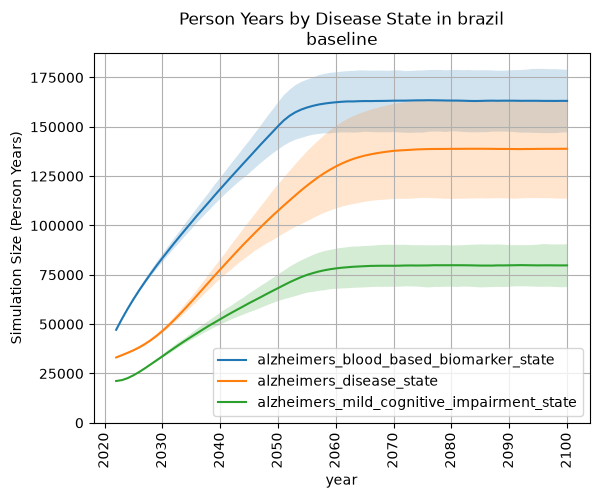

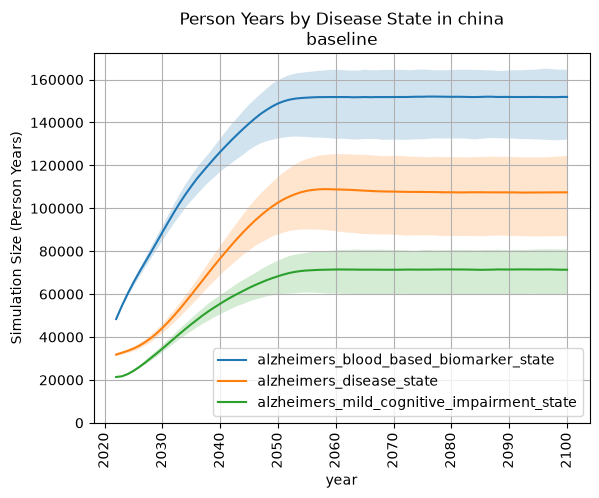

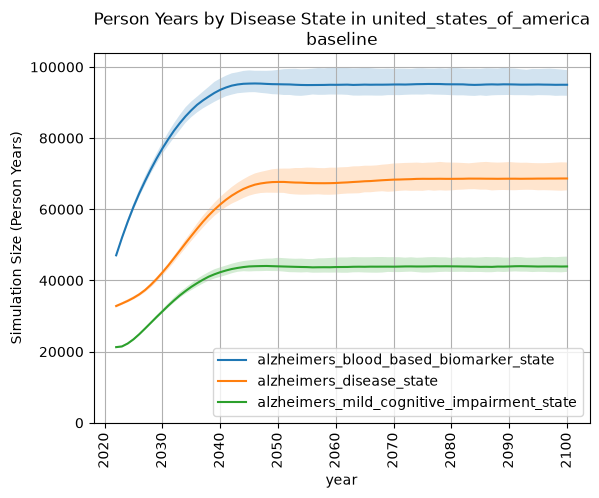

<Figure size 640x480 with 0 Axes>

In [71]:
scenario = 'baseline'
for location in person_time_total.location.unique():
    for sub_entity in person_time_total.sub_entity.unique():
        plot_data = person_time_total.query(
            "location == @location and sub_entity == @sub_entity and scenario == @scenario"
        )
        plt.plot(plot_data.event_year, plot_data["mean"], label=sub_entity)
        plt.fill_between(
            plot_data.event_year, plot_data["2.5%"], plot_data["97.5%"], alpha=0.2
        )
    plt.title(f"Person Years by Disease State in {location}\n{scenario}")
    plt.tick_params(axis="x", labelrotation=90)
    plt.xlabel("year")
    plt.ylabel("Simulation Size (Person Years)")
    plt.legend()
    plt.axis(ymin=0)
    plt.grid()
    plt.figure()

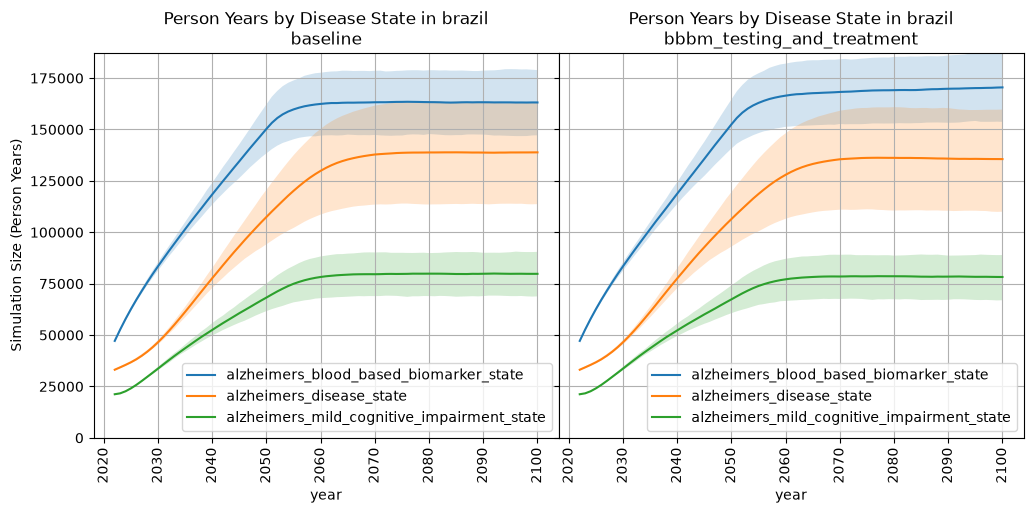

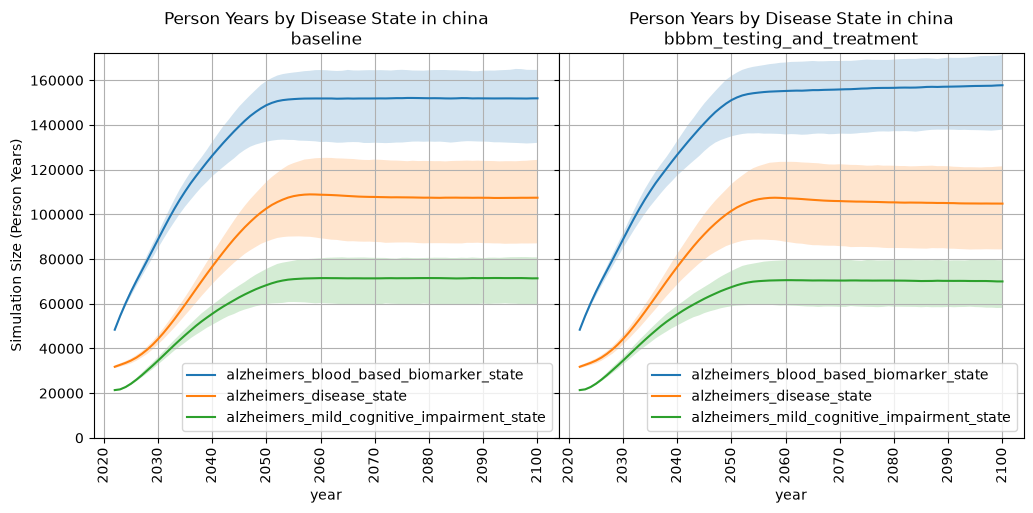

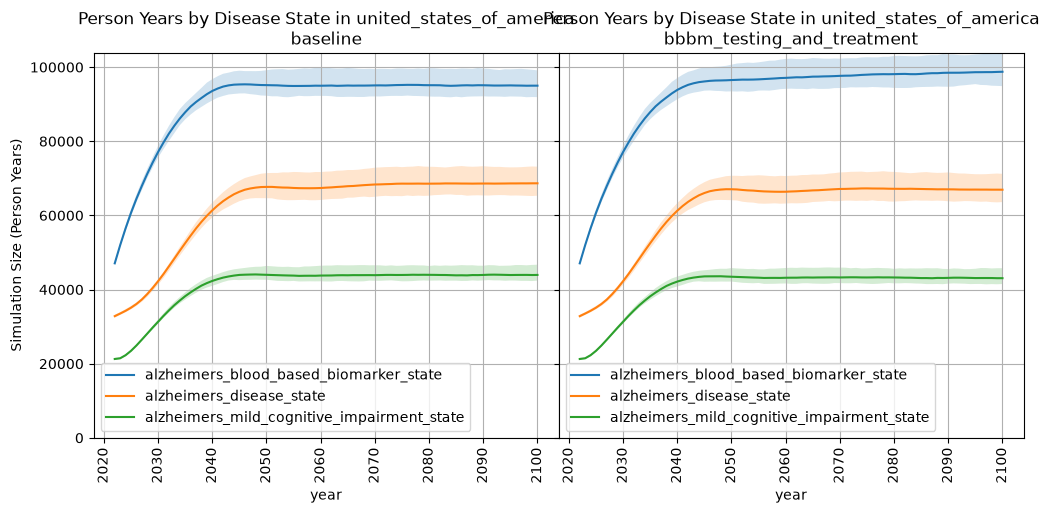

In [72]:
for location in person_time_total.location.unique():
    fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    plt.subplots_adjust(wspace=0)
    for scenario, ax in zip (['baseline', 'bbbm_testing_and_treatment'], axs):
        for sub_entity in person_time_total.sub_entity.unique():
            plot_data = person_time_total.query(
                "location == @location and sub_entity == @sub_entity and scenario == @scenario"
            )
            ax.plot(plot_data.event_year, plot_data["mean"], label=sub_entity)
            ax.fill_between(
                plot_data.event_year, plot_data["2.5%"], plot_data["97.5%"], alpha=0.2
            )
        ax.set_title(f"Person Years by Disease State in {location}\n{scenario}")
        ax.tick_params(axis="x", labelrotation=90)
        ax.set_xlabel("year")
        if scenario == 'baseline':
            ax.set_ylabel("Simulation Size (Person Years)")
        ax.legend()
        ax.axis(ymin=0)
        ax.grid()

plt.show()

In [73]:
!date

Thu Oct 29 13:30:31 PDT 2026
